<a href="https://colab.research.google.com/github/josecano8910/vocalization-acoustics-replication/blob/main/notebooks/vocalization_acoustics_replication.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import os
import numpy as np
import soundfile as sf

def create_synthetic_vocal_bout(output_path="data/sample_vocal_bout.wav", sr=22050):
    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    duration = 5.0
    t = np.linspace(0, duration, int(sr * duration), endpoint=False)

    rng = np.random.default_rng(42)
    audio = 0.01 * rng.normal(size=t.shape)

    syllables = [
        (0.6, 0.35, 380),
        (1.3, 0.28, 410),
        (2.5, 0.45, 360),
        (3.4, 0.30, 395),
    ]

    for start, dur, f0 in syllables:
        idx = (t >= start) & (t <= start + dur)
        t_syl = t[idx] - start
        envelope = np.sin(np.pi * (t_syl / dur)) ** 1.5
        pitch_contour = f0 + 25 * np.sin(2 * np.pi * 2.0 * t_syl)
        phase = 2 * np.pi * np.cumsum(pitch_contour) / sr
        signal = (
            0.5 * np.sin(phase) +
            0.25 * np.sin(2 * phase) +
            0.12 * np.sin(3 * phase)
        )
        audio[idx] += 0.4 * envelope * signal

    sf.write(output_path, audio, sr)
    print(f"Saved synthetic vocal bout to {output_path}")

createRecherche = create_synthetic_vocal_bout()


Saved synthetic vocal bout to data/sample_vocal_bout.wav


 syllable_id  onset_sec  offset_sec  duration_sec  mean_f0_hz  isi_sec
           1      0.023       4.992         4.969       391.8      NaN


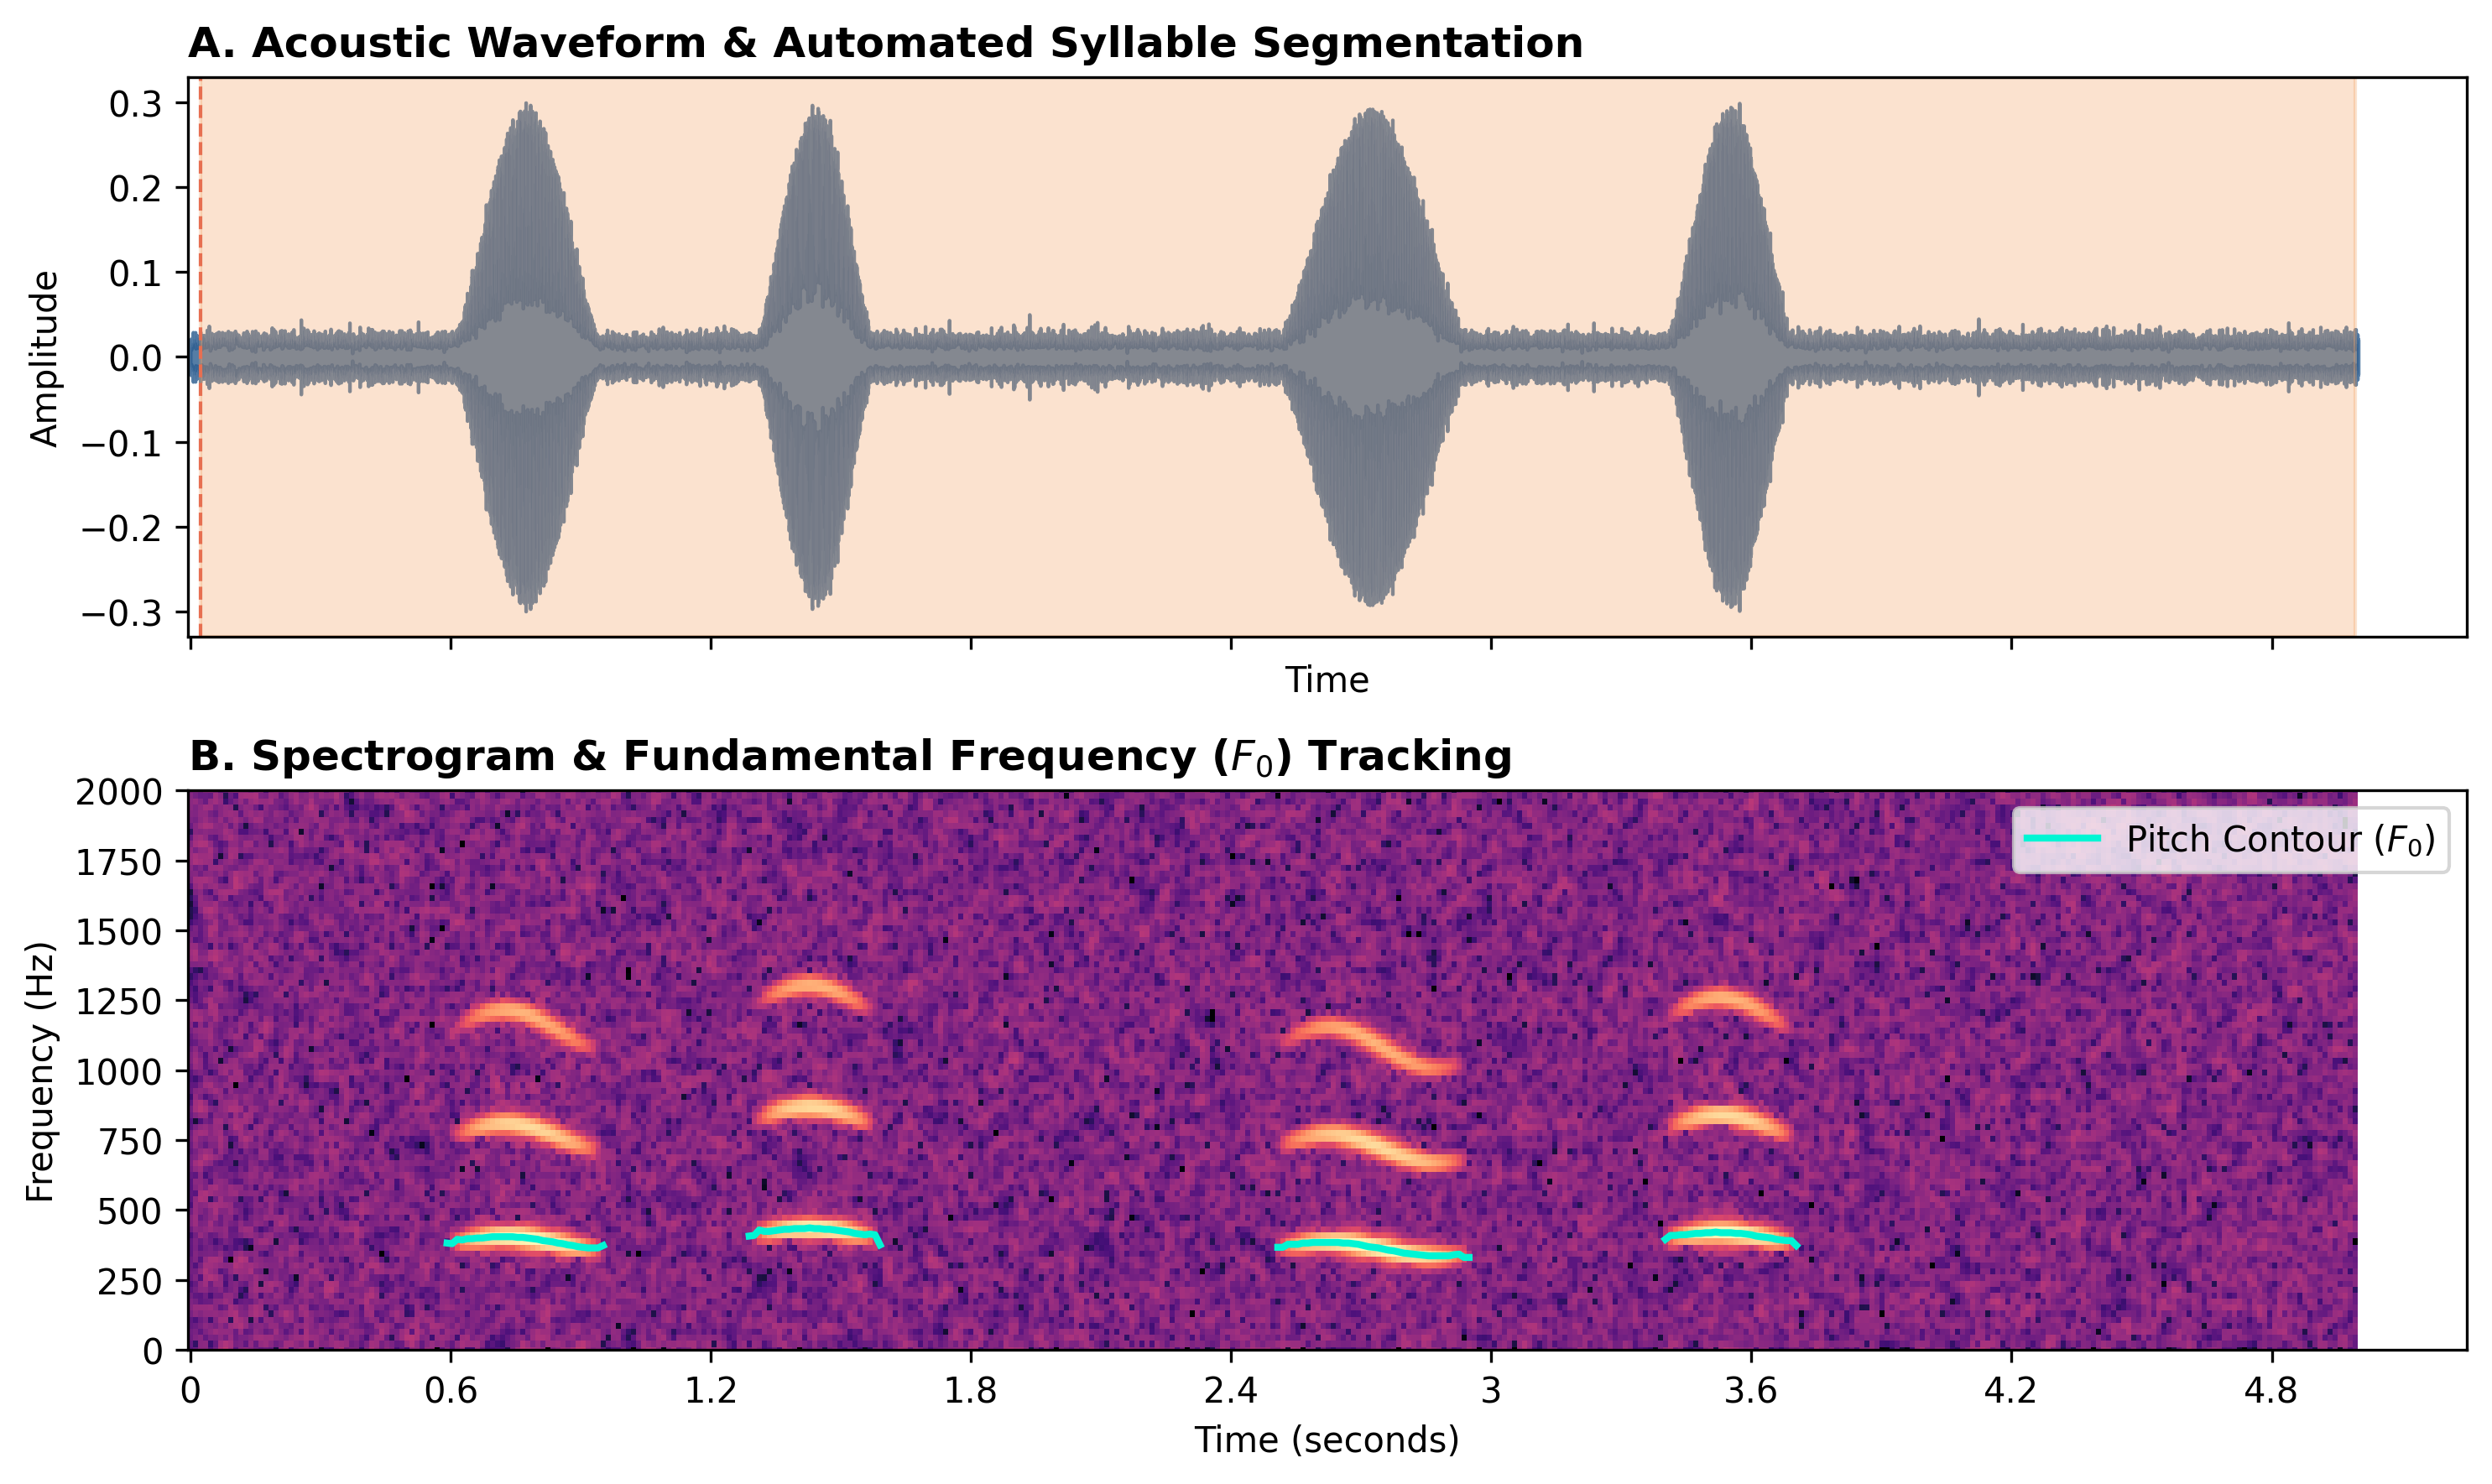

In [3]:
import pandas as pd
import librosa
import librosa.display
import matplotlib.pyplot as plt

def analyze_vocal_bout(audio_path="data/sample_vocal_bout.wav"):
    os.makedirs("figures", exist_ok=True)
    y, sr = librosa.load(audio_path, sr=None)
    intervals = librosa.effects.split(y, top_db=25, frame_length=1024, hop_length=256)

    f0, voiced_flag, _ = librosa.pyin(
        y, fmin=200, fmax=800, sr=sr, frame_length=1024, hop_length=256
    )
    times = librosa.times_like(f0, sr=sr, hop_length=256)

    records = []
    for start_sample, end_sample in intervals:
        start_sec = start_sample / sr
        end_sec = end_sample / sr
        dur_sec = end_sec - start_sec
        if dur_sec < 0.08:
            continue
        mask = (times >= start_sec) & (times <= end_sec)
        mean_f0 = np.nanmean(f0[mask]) if np.any(mask) else np.nan
        records.append({
            "syllable_id": len(records) + 1,
            "onset_sec": round(start_sec, 3),
            "offset_sec": round(end_sec, 3),
            "duration_sec": round(dur_sec, 3),
            "mean_f0_hz": round(float(mean_f0), 1)
        })

    df = pd.DataFrame(records)
    df["isi_sec"] = df["onset_sec"].diff().round(3)
    df.to_csv("data/extracted_syllable_metrics.csv", index=False)
    print(df.to_string(index=False))

    fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, dpi=300)
    librosa.display.waveshow(y, sr=sr, ax=axes[0], color="#2b5c8f", alpha=0.8)
    for _, row in df.iterrows():
        axes[0].axvspan(row["onset_sec"], row["offset_sec"], color="#f4a261", alpha=0.3)
        axes[0].axvline(row["onset_sec"], color="#e76f51", linestyle="--", linewidth=1)
    axes[0].set_title("A. Acoustic Waveform & Automated Syllable Segmentation", loc="left", fontweight="bold")
    axes[0].set_ylabel("Amplitude")

    S = librosa.amplitude_to_db(np.abs(librosa.stft(y, n_fft=1024, hop_length=256)), ref=np.max)
    librosa.display.specshow(S, sr=sr, hop_length=256, x_axis="time", y_axis="hz", ax=axes[1], cmap="magma")
    axes[1].plot(times, f0, color="#00f5d4", linewidth=2, label="Pitch Contour ($F_0$)")
    axes[1].set_ylim(0, 2000)
    axes[1].set_title("B. Spectrogram & Fundamental Frequency ($F_0$) Tracking", loc="left", fontweight="bold")
    axes[1].set_ylabel("Frequency (Hz)")
    axes[1].set_xlabel("Time (seconds)")
    axes[1].legend(loc="upper right")

    plt.tight_layout()
    plt.savefig("figures/vocal_bout_analysis.png")
    plt.show()

analyze_vocal_bout()
